# Coin-Guessing and the Illusion of Skill

**Question:** If 1,000 people guess coin flips at random, how many will look skilled just by luck?

**The idea:** Nobody here has any skill. Everyone is just guessing. But with enough people, a few will get a great score by pure luck. This is the same trap as testing many trading ideas and picking the one that looks best.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)    # fixed seed = same results every run

num_people = 1000     # how many people guess
num_guesses = 10      # how many guesses each person makes

## The exact answer
To get 8 or more right out of 10, a person needs exactly 8, 9 or 10 right. There are 45 ways to get 8, 10 ways to get 9, and 1 way to get 10. That is 56 ways.

In total there are 1,024 possible patterns of guesses (2 multiplied by itself 10 times). So the chance is 56 / 1024, about **5.5%**.

So out of 1,000 people, I expect about 55 to look skilled by luck.

In [2]:
exact_chance = 56 / 1024

print("Exact chance:", round(exact_chance * 100, 2), "%")
print("Expected lucky people out of 1000:", round(exact_chance * num_people))

Exact chance: 5.47 %
Expected lucky people out of 1000: 55


## Simulation
Now I check this with a computer. Each person makes 10 guesses and each guess is right half the time.

In [3]:
guess_is_right = rng.random((num_people, num_guesses)) < 0.5    # True = right guess
scores = guess_is_right.sum(axis=1)                             # right guesses per person

lucky_people = (scores >= 8).sum()
print("People who got 8 or more:", lucky_people)
print("Percent of people:", lucky_people / num_people * 100, "%")

pd.Series(scores).value_counts().sort_index()

People who got 8 or more: 62
Percent of people: 6.2 %


1       8
2      50
3     128
4     217
5     247
6     170
7     118
8      50
9       8
10      4
Name: count, dtype: int64

## More people, better "best" score
What if I add more people? Nobody gets any better at guessing, but the best score keeps going up.

In [4]:
rows = []
for people in [10, 100, 1000, 10000]:
    scores = (rng.random((people, 10)) < 0.5).sum(axis=1)
    rows.append({"number_of_people": people, "best_score_out_of_10": scores.max()})

more_people = pd.DataFrame(rows)
more_people

,number_of_people,best_score_out_of_10
0,10,7
1,100,9
2,1000,10
3,10000,10


## Repeating the experiment 200 times
One run could be a fluke. So I repeat the 1,000-person experiment 200 times and look at how the number of lucky people changes.

Smallest count: 35
Average count: 54.215
Largest count: 79


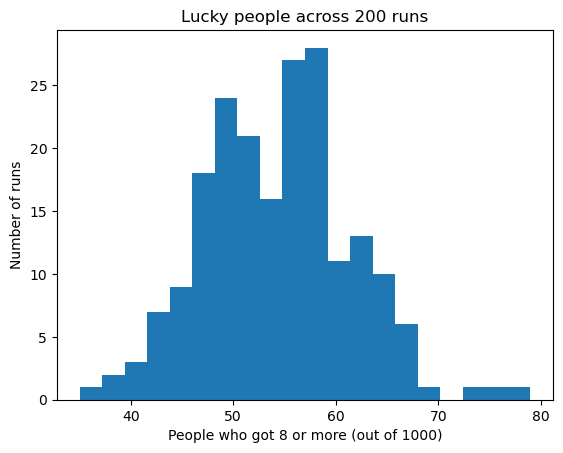

In [5]:
counts = []
for run in range(200):
    scores = (rng.random((1000, 10)) < 0.5).sum(axis=1)
    counts.append((scores >= 8).sum())

print("Smallest count:", min(counts))
print("Average count:", np.mean(counts))
print("Largest count:", max(counts))

plt.hist(counts, bins=20)
plt.xlabel("People who got 8 or more (out of 1000)")
plt.ylabel("Number of runs")
plt.title("Lucky people across 200 runs")
plt.show()

## Takeaway
- About 5% of random guessers look skilled by pure luck. This matches the exact answer of 56 / 1024.
- More people means a better-looking "best" score, even though nobody has any skill.
- The number of lucky people changes a little each run, but stays in a predictable range.

## Why it matters
Imagine testing 1,000 trading ideas that are all pure noise. A few of them will still look like winners in the past, just by luck. If you only look at the best one, you will think you found something real, then lose money when the luck runs out.

The more ideas you test, the better the "best" one looks, even when none of them work. That is why good researchers do two things:
- **Test on new data** that the idea has never seen
- **Use stricter standards** when they try many ideas

A good result only means something if it can survive these checks.

## Limitations
Every guess is a fair 50/50 and independent. Real markets are messier. "Looks skilled" here means 8 or more right out of 10, which is my own choice.